# 01 — ML Fundamentals

Key terms, splitting data, overfitting, regularization, honest validation, leakage and the end-to-end project workflow. These ideas apply to every model.

## What's in this notebook

- 1\. Key terms
- 2\. Train, validation and test splits
- 3\. Underfitting, overfitting and bias-variance
- 4\. Regularization: L1 vs L2
- 5\. Cross-validation
- 6\. Data leakage
- 7\. Class imbalance, class weights and baselines
- 8\. Learning curves
- 9\. ML project workflow (end to end)
- 10\. Diagnosis cheat table
- 11\. Interview questions
- 12\. In my own words

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, make_regression, make_moons, load_breast_cancer
from sklearn.model_selection import (train_test_split, cross_val_score, validation_curve, learning_curve,
                                     KFold, StratifiedKFold, GroupKFold, TimeSeriesSplit)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# NumPy 2.2 + Apple Accelerate prints harmless "encountered in matmul" RuntimeWarnings
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

# 1. KEY TERMS

**Types of machine learning**

| Type | Learns from | Examples |
|---|---|---|
| Supervised | labelled data (X and y) | classification (spam or not), regression (house price) |
| Unsupervised | X only, no labels | clustering, dimensionality reduction, anomaly detection |
| Semi-supervised | a few labelled rows plus many unlabelled ones | labelling is expensive (medical images) |
| Self-supervised | labels made from the data itself | predicting the next word: how LLMs are pre-trained |
| Reinforcement | rewards for actions in an environment | games, robotics, RLHF for LLMs |

Classification predicts a category; regression predicts a number.

**Parameters vs hyperparameters**
- **Parameters** are learned from the data during `fit`: the weights of a linear model, the split thresholds of a tree.
- **Hyperparameters** are set by us before training and control how the model learns or how complex it can be: `max_depth`, `alpha`, `C`, `n_neighbors`, the learning rate.
- Hyperparameters are chosen by comparing scores on validation data (section 5), never on the test set.

**Parametric vs non-parametric models**
- **Parametric:** a fixed number of parameters, however much data there is. Linear and logistic regression, Naive Bayes. Small and fast, but they assume a shape (for example a straight line).
- **Non-parametric:** the model grows with the data. KNN keeps every row, a decision tree grows more splits, a kernel SVM keeps more support vectors. Flexible, but they need more data and overfit more easily.
- "Non-parametric" doesn't mean "no parameters"; it means the number of parameters isn't fixed in advance.

**Discriminative vs generative models**
- **Discriminative** models learn P(y | x), the boundary between classes: logistic regression, SVM, trees.
- **Generative** models learn how the data itself is produced, P(x | y) and P(y), so they can also create new data: Naive Bayes, Gaussian mixtures, and in GenAI, LLMs and diffusion models.

Notation below: `X` = features (the inputs), `y` = target (what we predict).

# 2. TRAIN, VALIDATION AND TEST SPLITS

| Set | Used for | Typical share |
|---|---|---|
| Train | fitting the parameters | 60–80% |
| Validation | choosing hyperparameters, features and models | 10–20%, or cross-validation on the train set |
| Test | one final, unbiased score at the very end | 10–20% |

Once you make decisions by looking at the test score, it is no longer unbiased: you have tuned on it.

A random split is only right when the rows are independent. Match the split to how the model will be used:

| Split | Use when | scikit-learn |
|---|---|---|
| Stratified | classification, especially imbalanced: every part keeps the same class ratio | `train_test_split(..., stratify=y)`, `StratifiedKFold` |
| Group | many rows per user, patient or device: one entity must not be in both train and test | `GroupKFold`, `GroupShuffleSplit` |
| Time-based | the model predicts the future: train on the past, test on later data | `TimeSeriesSplit`, or a cut-off date |

`random_state` only fixes the shuffle so a run can be repeated; it doesn't make the model better.

In [2]:
X, y = make_classification(n_samples=1000, weights=[0.95, 0.05], random_state=0)

# Random vs stratified: share of the rare class in a 100-row test set, over 10 different seeds
for name, strat in [("random", None), ("stratified", y)]:
    shares = [train_test_split(X, y, test_size=0.1, stratify=strat, random_state=s)[3].mean() for s in range(10)]
    print(f"{name:>10} split: rare class is {min(shares):.0%} to {max(shares):.0%} of the test set (overall {y.mean():.1%})")

# Group split: 200 customers with 5 rows each
customer = np.repeat(np.arange(200), 5)
for name, (tr, te) in [("KFold", next(KFold(5, shuffle=True, random_state=0).split(X))),
                       ("GroupKFold", next(GroupKFold(5).split(X, y, groups=customer)))]:
    shared = np.intersect1d(customer[tr], customer[te])
    print(f"{name:>10}: {len(shared)} of {len(np.unique(customer[te]))} test customers also have rows in train")

# Time split: rows are assumed to be sorted by time
for tr, te in TimeSeriesSplit(n_splits=4).split(X):
    print(f"train rows {tr.min()}-{tr.max()}  ->  test rows {te.min()}-{te.max()}")

    random split: rare class is 1% to 9% of the test set (overall 5.4%)
stratified split: rare class is 5% to 5% of the test set (overall 5.4%)
     KFold: 132 of 132 test customers also have rows in train
GroupKFold: 0 of 40 test customers also have rows in train
train rows 0-199  ->  test rows 200-399
train rows 0-399  ->  test rows 400-599
train rows 0-599  ->  test rows 600-799
train rows 0-799  ->  test rows 800-999


A random split put the rare class at anywhere from 1% to 9% of the test set; stratifying kept it at 5% every time.
With a shuffled KFold, all 132 test customers also had rows in training, so the model can score well by recognizing customers. GroupKFold: 0 of 40.
TimeSeriesSplit always tests on rows that come after the training rows.

# 3. UNDERFITTING, OVERFITTING AND BIAS-VARIANCE

The goal is **generalization**: a low error on data the model has not seen. A high training score alone means little.

| | Underfitting (high bias) | Overfitting (high variance) |
|---|---|---|
| Train score | low | very high |
| Validation score | low, close to train | clearly lower than train |
| Cause | model too simple, weak features, too much regularization | model too flexible for the data, so it learns the noise |
| Fixes | more flexible model, better features, less regularization | more data, simpler model, more regularization, early stopping |

A good fit has both scores high and close together.

- **Bias**: error from assumptions that are too simple (a straight line through a curve). It stays however much data you add.
- **Variance**: how much the model changes when it is trained on a different sample. Two deep trees trained on two samples of the same data can look very different.

For squared error, the expected error on new data splits into three parts:

```text
expected error = bias² + variance + irreducible noise
```

More complexity lowers bias and raises variance, so validation error is usually U-shaped as complexity grows. No model can remove the noise term.

**More data reduces variance, not bias.** A model that is too simple stays too simple with more data (section 8).

How ensembles fit in:
- **Bagging** (random forest) averages many deep, high-variance trees trained on different samples, so it mainly lowers **variance**.
- **Boosting** (XGBoost, LightGBM) adds small, high-bias trees one after another, each fixing the errors left so far, so it mainly lowers **bias**.

The U-shape is a rule of thumb: very large neural networks can show **double descent**, where test error falls again after the model is big enough to fit the training data perfectly.

Below: a decision tree of growing depth on data where 10% of the labels are assigned at random, so there is noise to memorize. Scores are 5-fold cross-validation averages.

In [3]:
X, y = make_classification(n_samples=1000, n_features=20, n_informative=5, flip_y=0.1, random_state=42)
depths = [1, 2, 3, 4, 6, 8, 10, 15, None]
train, val = validation_curve(DecisionTreeClassifier(random_state=42), X, y, param_name="max_depth", param_range=depths, cv=5)

pd.DataFrame({"train": train.mean(axis=1), "validation": val.mean(axis=1), "gap": train.mean(axis=1) - val.mean(axis=1)},
             index=pd.Index([str(d) for d in depths], name="max_depth")).round(3)

,train,validation,gap
max_depth,,,
1,0.713,0.704,0.009
2,0.807,0.783,0.024
3,0.862,0.823,0.038
4,0.886,0.842,0.044
6,0.936,0.846,0.091
8,0.975,0.822,0.153
10,0.994,0.811,0.183
15,1.000,0.801,0.199
None,1.000,0.801,0.199


- **Depth 1 underfits:** train 0.713 and validation 0.704, both low and close.
- **Depth 6 is best** on validation (0.846). Depth 4 is almost as good (0.842) with half the gap.
- **No depth limit overfits:** the tree scores 1.000 on its training data, because it memorizes every row including the random labels, but only 0.801 on validation, a gap of 0.199.

Training accuracy keeps rising with depth. Only the validation score shows where to stop.

# 4. REGULARIZATION: L1 VS L2

Regularization adds a penalty for large weights to the loss, so the model prefers simpler solutions:

```text
L2 (Ridge):   loss + λ · Σ wᵢ²
L1 (Lasso):   loss + λ · Σ |wᵢ|
Elastic Net:  loss + a mix of both penalties
```

λ, the regularization strength, is a hyperparameter. Larger λ gives a simpler model: more bias, less variance.

| | L1 (Lasso) | L2 (Ridge) |
|---|---|---|
| Penalty | Σ \|w\| | Σ w² |
| Effect on weights | sets many to **exactly 0** | shrinks all of them, but almost never to exactly 0 |
| Result | sparse model, built-in feature selection | stable model, every feature kept |
| Correlated features | tends to keep one and drop the rest | spreads the weight across them |

**Why L1 gives exact zeros**
- Gradient view: the L1 penalty pulls each weight toward 0 with the same force λ, however small the weight already is. A weight that doesn't lower the loss by more than that is pushed all the way to 0 and stays there. The L2 pull is 2λw, which fades as w shrinks, so weights get small but stop short of 0.
- Geometric view: the L1 constraint region (|w₁| + |w₂| ≤ t) is a diamond with its corners on the axes. The loss contours usually touch it first at a corner, where one weight is 0. The L2 region is a circle, which has no corners.

**Naming in scikit-learn** (a common trap):

| Model | Parameter | Stronger regularization |
|---|---|---|
| `Ridge`, `Lasso`, `ElasticNet` | `alpha` = λ | larger `alpha` |
| `LogisticRegression`, `SVC`, `LinearSVC` | `C` = inverse of the strength (≈ 1/λ) | **smaller** `C` |

`LogisticRegression` is L2-regularized by default (`C=1.0`).
Scale the features first: the penalty compares weight sizes, and a weight's size depends on its feature's units.

In [4]:
# 10 features, only 3 of them matter (make_regression features are already on the same scale)
X, y, true_coef = make_regression(n_samples=100, n_features=10, n_informative=3, noise=10, coef=True, random_state=0)

# alpha values can't be compared between Ridge and Lasso: Lasso divides the squared error by 2n, Ridge doesn't
models = {"linear (no penalty)": LinearRegression(), "ridge alpha=10": Ridge(alpha=10), "lasso alpha=5": Lasso(alpha=5)}
coefs = pd.DataFrame({"true": true_coef} | {name: m.fit(X, y).coef_ for name, m in models.items()})
coefs = coefs.round(2) + 0.0                 # + 0.0 turns -0.0 into 0.0
print(coefs.to_string())
print("\nweights that are exactly 0:", (coefs == 0).sum().to_dict())

    true  linear (no penalty)  ridge alpha=10  lasso alpha=5
0   0.00                 0.85            0.35           0.00
1   0.00                -0.43            1.46           0.00
2  70.05                70.22           62.84          64.90
3  82.19                84.05           76.25          78.77
4   0.00                 1.59            1.91           0.00
5   0.00                 2.00            2.57           0.00
6  88.31                88.47           78.05          81.81
7   0.00                -2.49           -0.92           0.00
8   0.00                -0.72            0.35           0.00
9   0.00                -0.56           -0.06           0.00

weights that are exactly 0: {'true': 7, 'linear (no penalty)': 0, 'ridge alpha=10': 0, 'lasso alpha=5': 7}


Only features 2, 3 and 6 matter.
- **Lasso** sets all 7 useless weights to exactly 0 and keeps the 3 real ones, slightly shrunk (feature 6: 88.31 → 81.81).
- **Ridge** shrinks the big weights (feature 6: 88.31 → 78.05) but leaves all 10 non-zero. It shrinks the weights as a whole, not each one: when the big weights shrink, a small weight on a slightly correlated feature can pick up part of their job and grow (feature 1: −0.43 → 1.46).
- **Plain linear regression** gives every useless feature a small weight, up to 2.49 in size: it fits a little noise.

The same idea through `C` in `LogisticRegression`. Remember: small C = strong regularization.

In [5]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

rows = []
for C in [0.01, 0.1, 1, 10, 100]:
    l2 = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)).fit(X_train, y_train)
    l1 = make_pipeline(StandardScaler(), LogisticRegression(C=C, penalty="l1", solver="liblinear")).fit(X_train, y_train)
    rows.append({"C": C, "L2 weight size": np.linalg.norm(l2[-1].coef_), "L2 train": l2.score(X_train, y_train),
                 "L2 validation": l2.score(X_val, y_val), "L1 non-zero (of 30)": np.count_nonzero(l1[-1].coef_)})
pd.DataFrame(rows).set_index("C").round(3)

,L2 weight size,L2 train,L2 validation,L1 non-zero (of 30)
C,,,,
0.01,0.811,0.958,0.937,4
0.10,1.774,0.984,0.979,7
1.00,3.518,0.988,0.986,16
10.00,8.383,0.991,0.972,22
100.00,27.818,0.998,0.944,25


- **C = 0.01** (strong penalty): small weights (size 0.811) and validation accuracy 0.937: underfitting.
- **C = 100** (weak penalty): weights 34× larger (27.818), train accuracy 0.998 but validation down to 0.944: overfitting.
- **C = 1** is best here (validation 0.986).
- With L1, a smaller C keeps fewer features: 4 of 30 at C = 0.01, 25 at C = 100.

# 5. CROSS-VALIDATION

K-fold cross-validation splits the training data into K folds (usually 5 or 10). Each fold is the validation set once, while the model trains on the other K − 1 folds:

```text
fold:      1     2     3     4     5
round 1:  VAL   train train train train
round 2:  train VAL   train train train
...
round 5:  train train train train VAL

score = mean of the 5 validation scores (report the std too)
```

| CV does | CV does not |
|---|---|
| give a more reliable score than one split: every row is validated once | reduce overfitting: it only **measures** it |
| show how stable the score is (std across folds) | give you the final model: after choosing, refit on all training data |
| let you compare models and tune hyperparameters fairly | replace the test set: the best of many CV scores is optimistic, because you picked it |

In section 3, CV reported 0.801 for the unlimited tree; that didn't change the tree. The fix was a smaller `max_depth`, a setting that CV helped us choose.

With `cv=5`, scikit-learn uses StratifiedKFold for classifiers and plain KFold otherwise, without shuffling. Pass GroupKFold or TimeSeriesSplit when section 2 calls for them.
Other variants:
- **Leave-one-out (LOOCV):** K = number of rows. Uses almost all the data for training, but needs n fits and its estimate is noisy.
- **Repeated K-fold:** run K-fold several times with different shuffles and average, for a more stable score on small data.
- **Nested CV:** an inner CV loop tunes the hyperparameters and an outer loop scores the whole tuning process, so the final score isn't optimistic.

Tuning with GridSearchCV and nested CV is in `4-ml-pipelines-and-hyperparameter-tuning.ipynb`.

In [6]:
X, y = load_breast_cancer(return_X_y=True)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))

single = []
for seed in range(10):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    single.append(model.fit(X_tr, y_tr).score(X_te, y_te))
print(f"10 single 80/20 splits: accuracy from {min(single):.3f} to {max(single):.3f}")

scores = cross_val_score(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0))
print(f"5-fold CV: folds {scores.round(3)}  ->  {scores.mean():.3f} ± {scores.std():.3f}")

10 single 80/20 splits: accuracy from 0.965 to 1.000
5-fold CV: folds [0.956 0.974 0.982 1.    0.982]  ->  0.979 ± 0.014


Ten random splits of the same data and the same model give accuracies from 0.965 to 1.000: a 3.5-point spread from luck alone.
5-fold CV gives one number with an error bar: 0.979 ± 0.014.

# 6. DATA LEAKAGE

Leakage means the model gets information during training or evaluation that it won't have when it makes real predictions. The offline score looks great; the production score doesn't.

| Type | Example | Fix |
|---|---|---|
| Target leakage | predicting loan default from "amount recovered", which is only known after a default | for every feature ask: is it known at prediction time? |
| Preprocessing leakage | fitting a scaler, imputer, feature selector or target encoder on all rows before splitting | split first; put every fitted step inside a `Pipeline` |
| Train-test contamination | duplicate rows, or the same customer in both train and test | de-duplicate; group split |
| Time leakage | a random split of time-ordered data; features computed over the full history | time-based split; build features only from data before the prediction time |

Warning signs: a score that is too good to be true, or one feature that dominates the feature importances.

The demo uses 200 rows of pure noise (5,000 random features, random labels), so an honest score is about 0.5.
- **Leaky:** pick the 20 features that best match `y` using all rows, then cross-validate.
- **Correct:** put the selection inside a Pipeline, so each fold picks features from its own training rows only.

In [7]:
rng = np.random.default_rng(0)
X_noise, y_noise = rng.normal(size=(200, 5000)), rng.integers(0, 2, size=200)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

X_picked = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)        # the selector saw every row's label
leaky = cross_val_score(LogisticRegression(max_iter=1000), X_picked, y_noise, cv=cv).mean()
correct = cross_val_score(make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000)), X_noise, y_noise, cv=cv).mean()
print(f"feature selection before CV: {leaky:.3f}    inside a Pipeline: {correct:.3f}")

X, y = load_breast_cancer(return_X_y=True)
leaky = cross_val_score(LogisticRegression(max_iter=5000), StandardScaler().fit_transform(X), y, cv=cv).mean()
correct = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), X, y, cv=cv).mean()
print(f"scaling before CV:           {leaky:.3f}    inside a Pipeline: {correct:.3f}")

feature selection before CV: 0.795    inside a Pipeline: 0.545


scaling before CV:           0.979    inside a Pipeline: 0.979


Selecting on all rows found 20 noise features that happen to match these labels, and CV reported **0.795** on data with no signal at all. Inside the Pipeline the score falls to 0.545, close to the honest 0.5.

Scaling before the split made no difference here (0.979 both): a scaler only learns a mean and a std per feature, not the labels.
Use the Pipeline anyway. Steps that use the labels or create rows (feature selection, target encoding, oversampling) can leak a lot.

# 7. CLASS IMBALANCE, CLASS WEIGHTS AND BASELINES

With 95% negatives, a model that always says "negative" is 95% accurate and useless.

- **Fit a baseline first.** `DummyClassifier(strategy="most_frequent")` for classification, `DummyRegressor()` (predicts the mean) for regression. A model is worth its margin over the baseline, not its raw score.
- **Use metrics that look at the rare class:** precision, recall, F1, PR-AUC. They are covered in `2-ml-metrics.ipynb`.
- **Class weights** make mistakes on the rare class cost more in the loss. No new data is created. `class_weight="balanced"` uses:

```text
weight of a class = n_samples / (n_classes × n_samples_in_that_class)
```

- Other options: move the decision threshold, or resample (over/undersampling, SMOTE) inside the training folds only.

In [8]:
X, y = make_classification(n_samples=5000, n_features=10, n_informative=4, weights=[0.95, 0.05], class_sep=1.5, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
print("balanced class weights:", (len(y_train) / (2 * np.bincount(y_train))).round(2))

models = {"dummy (always majority)": DummyClassifier(strategy="most_frequent"),
          "logistic regression": LogisticRegression(),
          "logistic, class_weight='balanced'": LogisticRegression(class_weight="balanced")}
rows = []
for name, m in models.items():
    pred = m.fit(X_train, y_train).predict(X_test)
    rows.append({"model": name, "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred, zero_division=0),
                 "recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred)})
pd.DataFrame(rows).round(3)

balanced class weights: [0.53 9.31]


,model,accuracy,precision,recall,F1
0,dummy (always majority),0.947,0.000,0.000,0.000
1,logistic regression,0.960,0.885,0.288,0.434
2,"logistic, class_weight='balanced'",0.807,0.176,0.712,0.283


- The **dummy** scores 0.947 accuracy and finds none of the positives (recall 0).
- **Plain logistic regression** is barely more accurate (0.960) and finds only 29% of the positives (recall 0.288).
- **Balanced weights** (9.31 for a positive row, 0.53 for a negative one) raise recall to 0.712, at the cost of precision (0.885 → 0.176) and accuracy (0.807).

Which trade is better depends on what a missed positive costs compared with a false alarm.

# 8. LEARNING CURVES

A learning curve plots the train and validation scores as the training set grows. It answers: will more data help?

| Shape | Diagnosis | More data? |
|---|---|---|
| both curves low, close together and flat | high bias | no: use a more flexible model or better features |
| large gap, validation still rising | high variance | yes; or regularize or simplify |
| both high and close | good fit | not needed |

logistic regression (a straight line): 50 rows: train 0.856, val 0.844  |  4000 rows: train 0.857, val 0.856


decision tree, max_depth=8: 50 rows: train 1.000, val 0.878  |  4000 rows: train 0.959, val 0.934


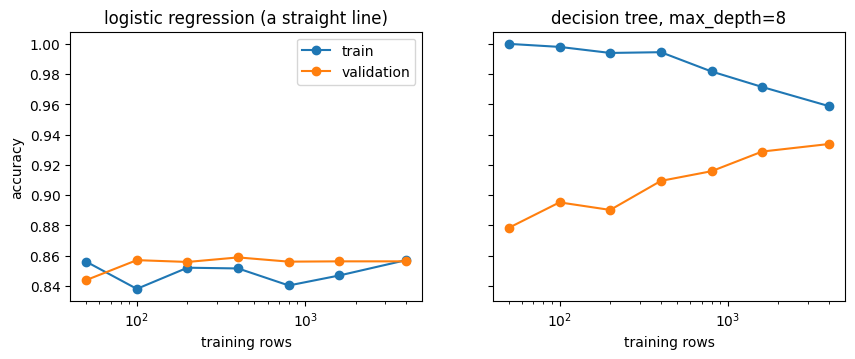

In [9]:
X, y = make_moons(n_samples=5000, noise=0.25, random_state=0)
sizes = [50, 100, 200, 400, 800, 1600, 4000]
models = {"logistic regression (a straight line)": LogisticRegression(),
          "decision tree, max_depth=8": DecisionTreeClassifier(max_depth=8, random_state=0)}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    n, train, val = learning_curve(model, X, y, train_sizes=sizes, cv=StratifiedKFold(5, shuffle=True, random_state=0))
    train, val = train.mean(axis=1), val.mean(axis=1)
    print(f"{name}: {n[0]} rows: train {train[0]:.3f}, val {val[0]:.3f}  |  {n[-1]} rows: train {train[-1]:.3f}, val {val[-1]:.3f}")
    ax.plot(n, train, marker="o", label="train")
    ax.plot(n, val, marker="o", label="validation")
    ax.set(xscale="log", xlabel="training rows", title=name)
axes[0].set_ylabel("accuracy")
axes[0].legend()
plt.show()

- **Straight line:** both curves stay between about 0.84 and 0.86 whether it trains on 50 rows or 4,000 (validation 0.844 → 0.856), with no gap. High bias: more data doesn't help.
- **Tree:** a large gap at 50 rows (train 1.000, validation 0.878) that shrinks to 0.025 at 4,000 rows, while validation keeps rising to 0.934. High variance: more data helps.

# 9. ML PROJECT WORKFLOW (END TO END)

"Walk me through an ML project" is one of the most common interview questions. A good answer follows these steps:

```text
 1. Problem    What decision will the model support? What does each kind of error cost?
               Is ML needed at all, or would a simple rule do?
 2. Metric     One offline metric that matches the cost (recall, PR-AUC, RMSE, ...)
               and the business metric it should move (revenue, churn, time saved).
 3. Data       Sources, labels, time range. Leakage check: is each feature known at prediction time?
 4. Split      Train / validation / test that matches real use: stratified, group or time-based.
 5. Baseline   A dummy model or a simple rule, so later scores mean something.
 6. Features   Missing values, outliers, encoding, scaling, new features, all inside a Pipeline.
 7. Models     Start simple (linear model, small tree), then boosting; tune with cross-validation.
 8. Evaluate   Score the test set once; error analysis; check slices (segment, region, device).
 9. Deploy     Save the whole pipeline; serve it behind an API, in batch or in real time.
10. Monitor    Data drift, prediction drift, the live metric; retrain when it drops.
```

**Error analysis** (step 8): read the wrong predictions, group them (by class, segment or input type) and fix the biggest group first, with more data for it, a new feature or corrected labels.

Steps 6 to 10 are covered in notebooks 3 to 6 of this folder.

# 10. DIAGNOSIS CHEAT TABLE

| You see | Likely cause | Try |
|---|---|---|
| train and validation both low | high bias (underfitting) | more flexible model, better features, less regularization |
| train high, validation much lower | high variance (overfitting) | more data, more regularization, simpler model, early stopping |
| score too good to be true | leakage | is each feature known at prediction time? Pipeline; group or time split |
| high accuracy, rare-class recall near 0 | class imbalance | baseline, precision/recall/F1, class weights, threshold |
| scores jump between folds or seeds | small or noisy data | more folds, repeated CV, report mean ± std |
| good CV score, poor in production | leakage, wrong split, or data drift | time-based split, monitor the input data |
| a score, but no idea what to fix next | | error analysis: read the wrong predictions and group them by class, segment or input type |

# 11. INTERVIEW QUESTIONS

### Q1. Explain overfitting and the bias-variance trade-off in 30 seconds.
A model overfits when it learns the noise in its training data: a very high train score but a clearly lower validation score.
Underfitting is the opposite: both scores are low. Bias is error from assumptions that are too simple; variance is how much
the model changes with the training sample. More complexity lowers bias and raises variance, so we choose the complexity and
regularization that give the best cross-validated score.

### Q2. How do you tell overfitting from underfitting?
Compare train and validation scores. Both low and close: underfitting. Train much higher than validation: overfitting.
A learning curve shows which one it is and whether more data would help.

### Q3. How do you reduce overfitting?
More data, a simpler model (smaller `max_depth`, fewer features), stronger regularization (larger `alpha`, smaller `C`, dropout),
early stopping, or bagging. Cross-validation is not a fix: it measures overfitting and helps choose these settings.

### Q4. Will more data fix my model?
Only if the problem is high variance. If the learning curves are low, flat and close together (high bias), more data won't help;
use a more flexible model or better features.

### Q5. L1 vs L2? Why does L1 give exact zeros?
L2 adds λΣw² and shrinks all weights. L1 adds λΣ|w| and sets many weights to exactly 0, so it also selects features.
L1 pulls every weight toward 0 with the same force λ, so weights that don't help enough reach 0; the L2 pull (2λw) fades
as the weight shrinks. Geometrically, the L1 region is a diamond with corners on the axes, where some weights are 0.

### Q6. What do `alpha` and `C` mean in scikit-learn?
Both set regularization. `alpha` (Ridge, Lasso) is the strength: larger means stronger. `C` (LogisticRegression, SVC) is the
inverse: smaller C means stronger regularization, and a very large C means almost none.

### Q7. Why separate validation and test sets? When is a random split wrong?
Validation is for making choices; the test set gives one unbiased score at the end, and it stops being unbiased once you tune
on it. A random split is wrong when rows aren't independent: use a group split when one entity has many rows, and a time-based
split when the model predicts the future.

### Q8. What is data leakage? Give examples.
Information the model won't have at prediction time reaches training or evaluation: a feature known only after the outcome,
a scaler or feature selector fitted on all rows, the same customer in train and test, or future rows in a random split of
time-ordered data. Prevent it by asking "is this known at prediction time?", splitting first, using a Pipeline, and using
group or time-based splits.

### Q9. Your model has 99% accuracy. What do you check?
The baseline (with 99% negatives, always predicting negative also scores 99%), the precision and recall on the rare class,
and leakage: features too close to the target, or duplicates across the split.

### Q10. Why is cross-validation better than one split, and what are its limits?
One split can be lucky or unlucky (10 splits of the same data ranged from 0.965 to 1.000 above). CV averages K scores and shows
their spread. It costs K trainings, it doesn't reduce overfitting, and the best CV score after tuning is optimistic, so keep
a test set for the final number.

### Q11. Walk me through an ML project end to end.
Define the problem and what errors cost, pick a metric that matches, collect data and check for leakage, split the way the
model will be used, build a baseline, engineer features inside a Pipeline, try simple models then stronger ones with CV,
score the test set once and do error analysis, deploy the pipeline behind an API, then monitor drift and retrain (section 9).

### Q12. Parametric vs non-parametric models?
Parametric models have a fixed number of parameters whatever the data size (linear and logistic regression, Naive Bayes):
fast and small, but they assume a shape. Non-parametric models grow with the data (KNN, decision trees, kernel SVM):
flexible, but they need more data and overfit more easily.

### Q13. How do bagging and boosting relate to bias and variance?
Bagging averages many high-variance models trained on different samples, so it lowers variance (random forest).
Boosting adds weak, high-bias models one by one, each correcting the remaining errors, so it lowers bias (XGBoost).

### Q14. Supervised vs unsupervised vs self-supervised learning?
Supervised learns from labelled pairs (X, y). Unsupervised finds structure in X alone (clusters, components).
Self-supervised creates its labels from the data, such as the next word in a sentence; that's how LLMs are pre-trained,
before supervised fine-tuning and RLHF (reinforcement learning from human feedback).

### Q15. Discriminative vs generative models?
A discriminative model learns P(y | x) directly, the boundary between classes (logistic regression, SVM).
A generative model learns how the data is produced, P(x | y) and P(y), so it can also generate new samples
(Naive Bayes, Gaussian mixtures, LLMs, diffusion models).

# 12. IN MY OWN WORDS

Write this from memory, without looking above:

- Overfitting vs underfitting, and how I spot each:
- Why L1 gives zeros and L2 doesn't:
- What cross-validation does and doesn't do:
- Two kinds of leakage I would check for in a new project:
- When more data helps:

- How I'd walk an interviewer through an ML project: